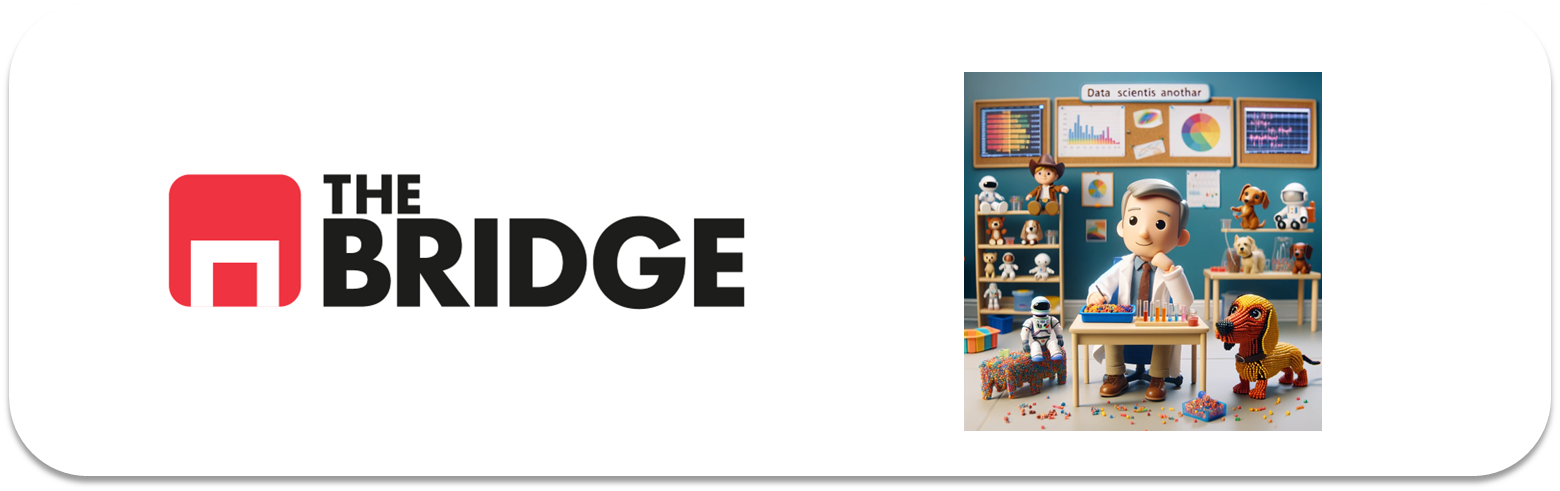

## Análisis de Datos: Frecuencias

### Preliminares

Antes de entrar en materia, ejecuta las celdas siguientes. (Vamos a usar ya librerías de visualización, pero para **analizar** los datos, no para presentarlos; eso lo veremos en el sprint de visualización.)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import pinta_distribucion_categoricas  # funciones de visualización del curso

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

In [2]:
categoricas_seguros = [ # Sí, conviene pasar la tabla a listas python :-)
    "state",
    "response",
    "coverage",
    "education",
    "employmentstatus",
    "gender",
    "location_code",
    "marital_status",
    "policy_type",
    "policy",
    "renew_offer_type",
    "sales_channel",
    "vehicle_class",
    "vehicle_size"
]


### Frecuencias absolutas
La primera pregunta que le hacemos a una variable categórica es: **¿cuántas veces aparece cada valor?** Esa es su **tabla de frecuencias absolutas**: el número de veces que se repite cada valor de la variable. Nosotros la obtenemos con `value_counts()`.

Al valor que más se repite lo llamamos **moda**; la retomaremos en el siguiente notebook junto con la media y la mediana.

#### Seguros: Frecuencias absolutas

In [3]:
for col in categoricas_seguros:
    print(df_seguros[col].value_counts(), "\n")

state
California    3150
Oregon        2601
Arizona       1703
Nevada         882
Washington     798
Name: count, dtype: int64 

response
No     7826
Yes    1308
Name: count, dtype: int64 

coverage
Basic       5568
Extended    2742
Premium      824
Name: count, dtype: int64 

education
Bachelor                2748
College                 2681
High School or Below    2622
Master                   741
Doctor                   342
Name: count, dtype: int64 

employmentstatus
Employed         5698
Unemployed       2317
Medical Leave     432
Disabled          405
Retired           282
Name: count, dtype: int64 

gender
F    4658
M    4476
Name: count, dtype: int64 

location_code
Suburban    5779
Rural       1773
Urban       1582
Name: count, dtype: int64 

marital_status
Married     5298
Single      2467
Divorced    1369
Name: count, dtype: int64 

policy_type
Personal Auto     6788
Corporate Auto    1968
Special Auto       378
Name: count, dtype: int64 

policy
Personal L3     3426
Perso

Así de primeras parece que las modas (salvo en el caso del género) son representativas, aunque haya casos donde haya cierta competencia. Esa dominancia podría ser ya algo a destacar (todo lo que sobresalga, recuerdas) sobre todo en el sentido de que quizás la empresa tenga un perfil excesivamente dominante, lo que pudiera ser buscado o no, pero sería algo a investigar. En cualquier caso ver tantas variables categóricas en números no es lo más cómodo para analizar así que...

#### Visualización

Las frecuencias es una de esas medidas, como todas las de distribución de datos, que más que leer es mejor visualizar para analizarlas. Así que empleemos la función `pinta_distribucion_categoricas` de `bootcampviztools` para visualizar nuestras frecuencias:

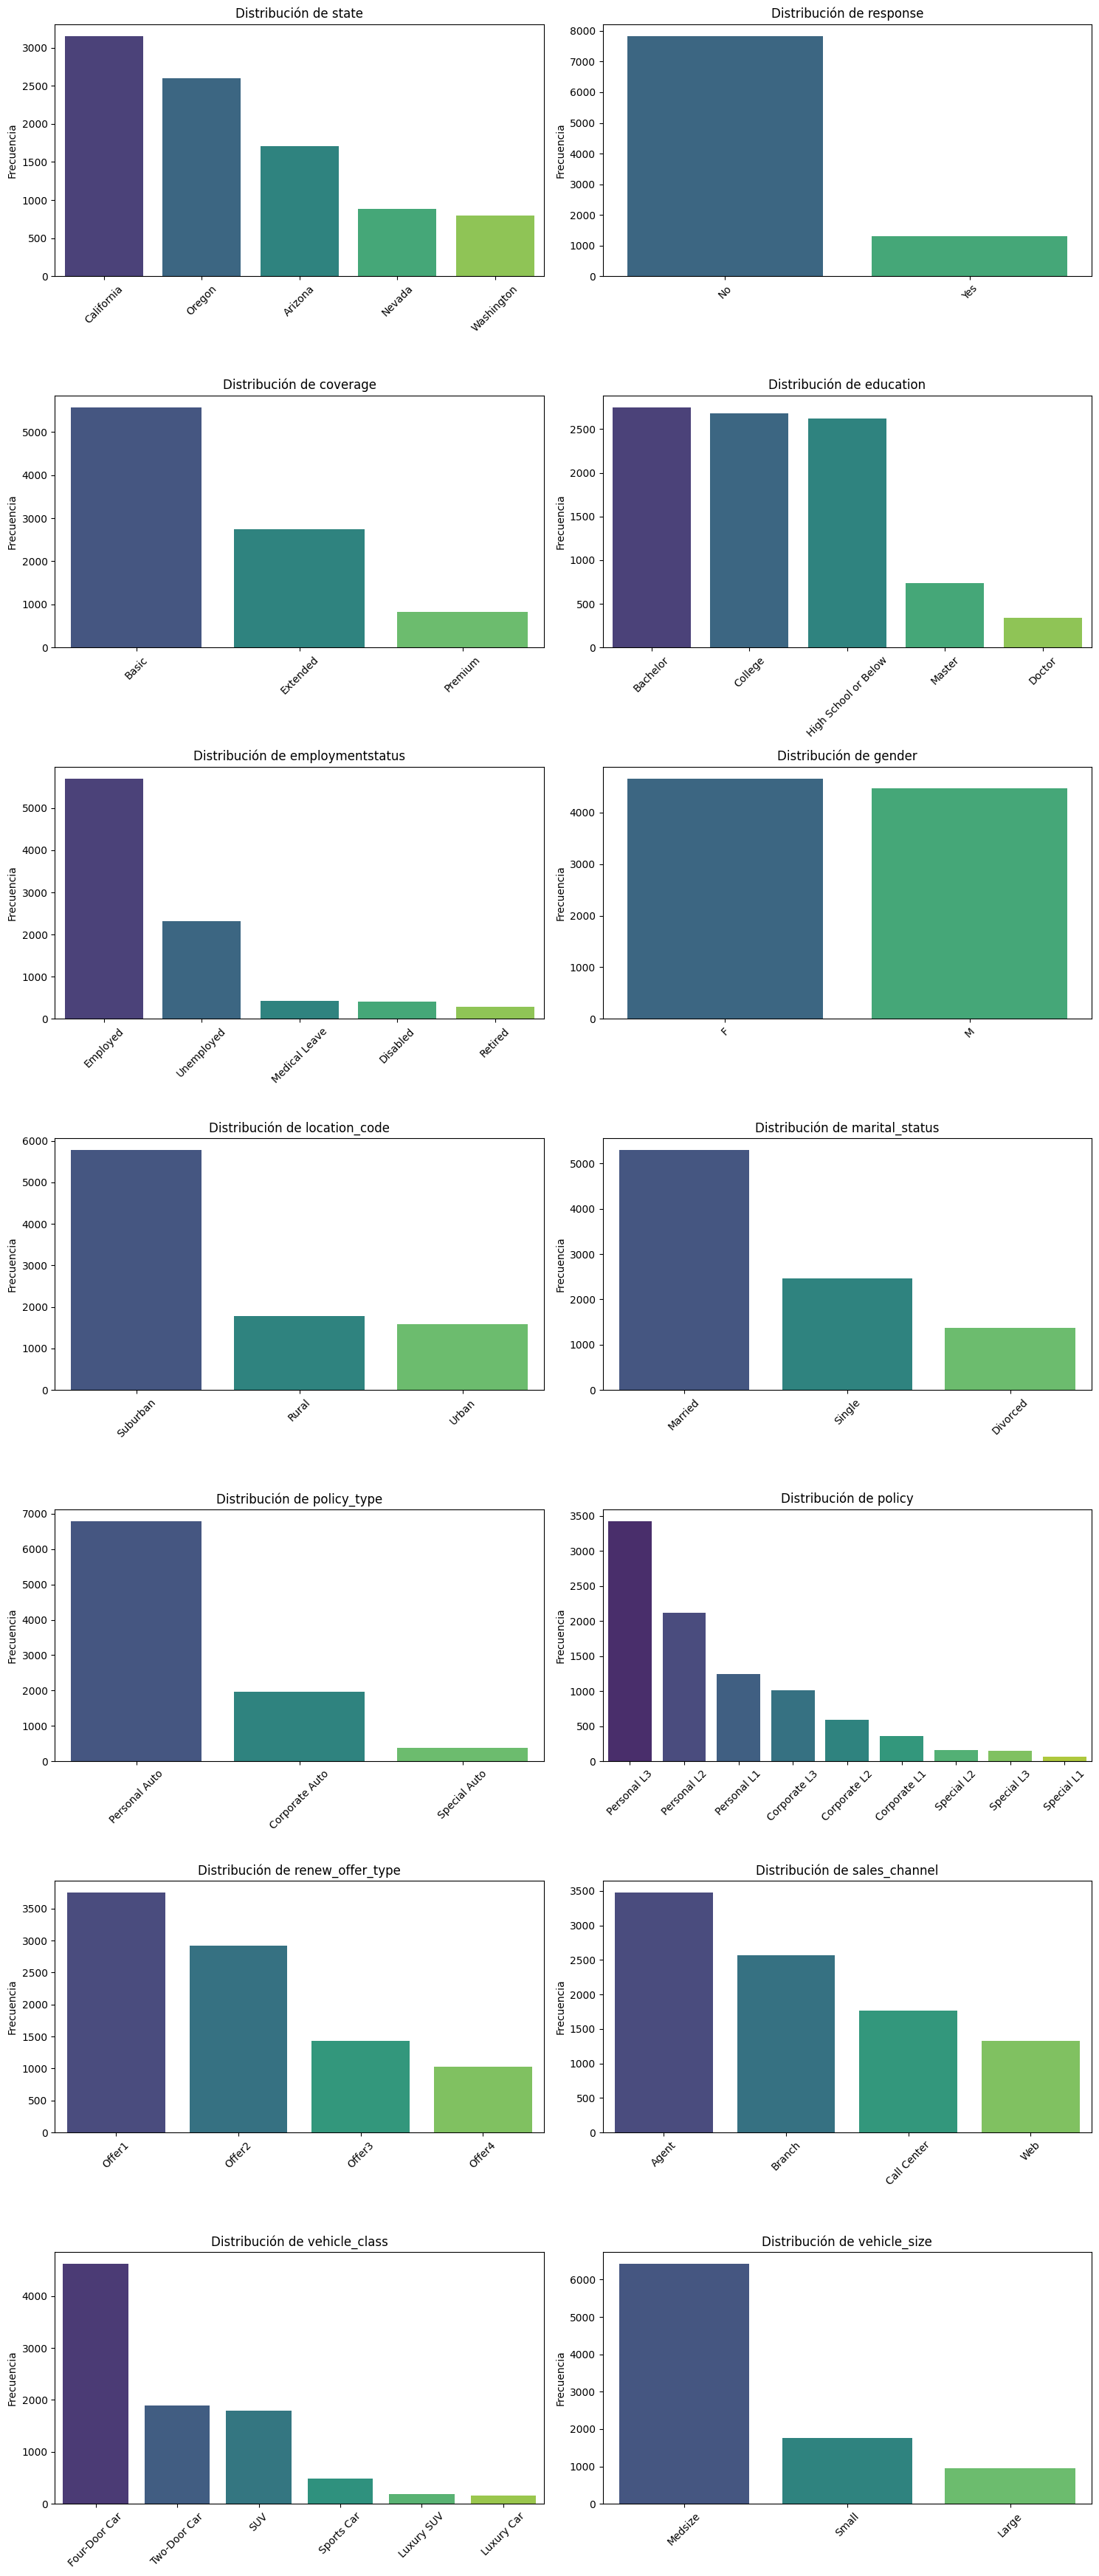

In [4]:
pinta_distribucion_categoricas(df_seguros, categoricas_seguros)

Aquí ya es más visual y se pueden ver más cosas (siempre lo que destaque, lo que sobresalga y lo que no):

* Response que es una de las importantes, hay una importante diferencia entre No y Yes en favor del No. Claramente ya tenemos un punto destacado: Tenemos un claro desbalanceo en la respuesta a nuestras campañas de marketing ¿es aceptable?¿está en línea con el mercado?
* California y Oregon son los estados con más clientes, ¿son los estados con mayor CLV por cliente?¿como son las respuestas en dichos estados? 
* Claramente dominan los clientes con 4-puertas, ¿qué representa en términos de CLV, se mantiene esa dominancia?

Y luego seguiría analizando en orden descendente según la importancia que establecimos en los primeros pasos, probablemente centrándome en las demográficas porque así lo pidieron desde dirección e importante relacionandolo con nuestras variables directoras o target.

Antes de seguir, observa que con esas escalas a veces es difícil estudiar o comparar los valores entre sí... Por eso la recomendación es pasar a frecuencias relativas.

### Frecuencia Relativa

Igualmente también podemos calcular la **frecuencia relativa** de cada conteo con respecto al total de valores de la muestra, de esta manera comprobamos la proporción de cada valor, lo que muchas veces facilita las comparaciones.

#### Seguros: Frecuencia relativa


In [5]:
for col in categoricas_seguros:
    print(df_seguros[col].value_counts(normalize=True).round(3), "\n")  # normalize=True -> proporciones

state
California    0.345
Oregon        0.285
Arizona       0.186
Nevada        0.097
Washington    0.087
Name: proportion, dtype: float64 

response
No     0.857
Yes    0.143
Name: proportion, dtype: float64 

coverage
Basic       0.61
Extended    0.30
Premium     0.09
Name: proportion, dtype: float64 

education
Bachelor                0.301
College                 0.294
High School or Below    0.287
Master                  0.081
Doctor                  0.037
Name: proportion, dtype: float64 

employmentstatus
Employed         0.624
Unemployed       0.254
Medical Leave    0.047
Disabled         0.044
Retired          0.031
Name: proportion, dtype: float64 

gender
F    0.51
M    0.49
Name: proportion, dtype: float64 

location_code
Suburban    0.633
Rural       0.194
Urban       0.173
Name: proportion, dtype: float64 

marital_status
Married     0.58
Single      0.27
Divorced    0.15
Name: proportion, dtype: float64 

policy_type
Personal Auto     0.743
Corporate Auto    0.215
Specia

Y como antes, es mejor visualizar (aunque en este caso tener los número es interesante):


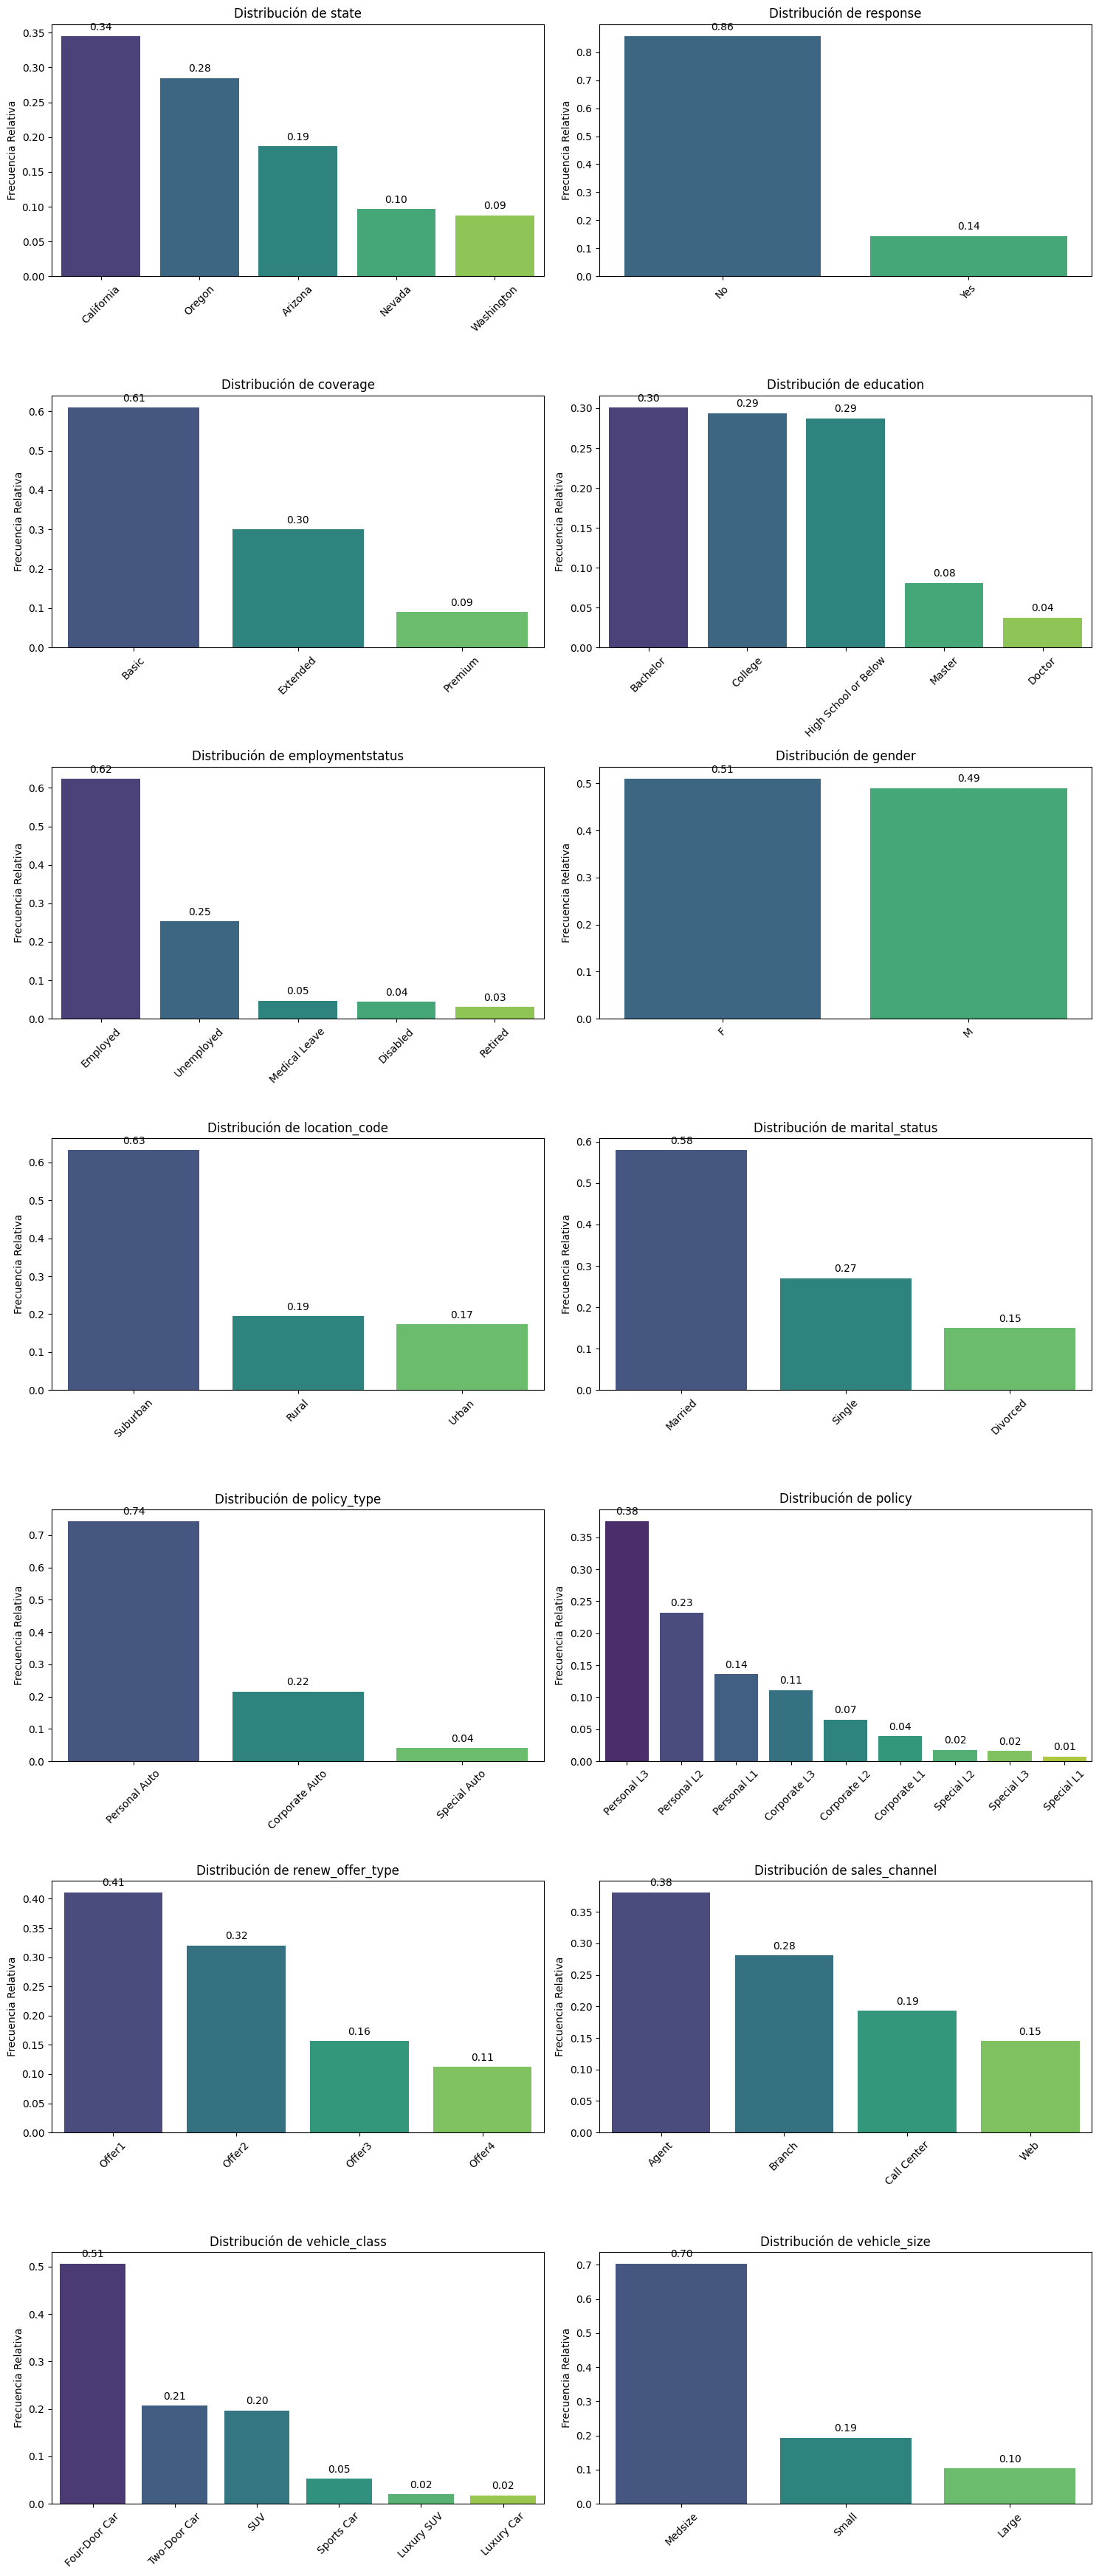

In [6]:
pinta_distribucion_categoricas(df_seguros, categoricas_seguros, relativa=True, mostrar_valores=True)

Observa las gráficas e intenta hacer una pequeña lista de cosas que sería interesante investigar al hilo de las preguntas que nos hicieron. Algunas de mis sugerencias:
* Respuesta, 14% vs 86%. ¿Qué segmento o conjunto de segmentos responde mejor?¿Qué segmento o conjunto de segmentos responde peor? ¿Que oferta es la mejor "atendida"? ¿Va en consonancia con la distribución de ofertas realizadas?
* Respuesta y CLV por Estado, respuesta y CLV por estado civil, respuesta y CLV por situación laboral. En estas tres hay una cierta dominancia, se mantiene en términos de CLV y respuesta (respuesta siempre hace referencia a la variable de respuesta a las campañas de renovación).

[En el siguiente notebook pasamos a las variables numéricas: ¿alrededor de qué valor se concentran? Medidas de tendencia central]